<div style="border-left:6px solid #275DAD; padding:16px 22px; background:#EFF4FC; color:#183153;">
<p style="font-size:13px; letter-spacing:2px; margin:0;">A FIRST COURSE IN LANGUAGE MODELS · JULIA</p>
<h1 style="margin:8px 0;">From Tokens to a Tiny GPT</h1>
<p style="font-size:18px; margin:0;">Turn text into numbers. Learn representations. Attend to context. Train a language model.</p>
</div>

You know what a neural network, a loss function, and gradient descent are. You do **not** need any previous NLP knowledge.

We will build a small **decoder-only Transformer** from random parameters, using Julia and Flux. Every figure, training sentence, and model component is created inside this notebook. No API, pretrained weights, or data download is needed after the Julia project dependencies are installed.

**The goal:** see the whole mechanism, rather than obtain a general-purpose chatbot. Our final model learns a small, deliberately constructed language of economics-themed sentences.

## A reading map

| Part | Question | What you will run |
|---|---|---|
| 1–3 | How does text become a trainable input? | A tokenizer, an embedding lookup, and one embedding update |
| 4–6 | How does a token use context? | Position information, hand-sized attention, and a causal mask |
| 7–9 | How do we assemble and train a tiny GPT? | A two-layer Transformer and next-token training |
| 10–12 | What did it learn, and how do we check? | Held-out loss, context probes, generation, and causal checks |

**First pass:** read the explanations and run the cells in order. The multi-head tensor reshaping is marked as a second-pass detail. Restart the Julia kernel before a fresh full run, since the notebook defines custom Julia types.

## 0. Setup: use the existing Julia project

Select the **Julia 1.12** kernel. Start Jupyter from the repository root or its `notebooks/` directory. The cell finds the enclosing `Project.toml` and activates it. If dependencies are missing, run `using Pkg; Pkg.instantiate()` once in that project.

All calculations below run on the **CPU**. The first run includes Julia compilation; elapsed time is printed during training. `Float32` keeps the model small. One BLAS thread avoids overhead on these tiny matrices.

In [1]:
using Pkg
function enclosing_project(start=pwd())
    folder = abspath(start)
    while !isfile(joinpath(folder, "Project.toml"))
        parent = dirname(folder)
        parent == folder && error("Start the kernel in this repository or notebooks/.")
        folder = parent
    end
    folder
end
Pkg.activate(enclosing_project())
ENV["GKSwstype"] = "100"  # render plots without opening a desktop window
using Flux, Random, LinearAlgebra, Statistics, Printf, Plots
BLAS.set_num_threads(1)
Random.seed!(20261027)
default(fontfamily="Helvetica", titlefontsize=12, guidefontsize=10,
        tickfontsize=9, legendfontsize=9, linewidth=2,
        framestyle=:box, gridalpha=0.15, size=(850, 380),
        left_margin=10Plots.mm, right_margin=7Plots.mm,
        bottom_margin=12Plots.mm, top_margin=6Plots.mm)
blue, green, gold, purple = "#275DAD", "#21A179", "#DE9B35", "#8854C0"
@printf("Julia %s | Flux %s | Plots %s | CPU\n",
        VERSION, pkgversion(Flux), pkgversion(Plots))

  Activating project at `C:\Users\30945\Desktop\Yuxuan ZHAO\minnesota\Research\DeepLearningMacro`
Julia 1.12.4 | Flux 0.16.10 | Plots 1.41.6 | CPU


## 1. NLP starts with a prediction problem

**Natural Language Processing (NLP)** studies computational tasks involving human language: classification, search, translation, and generation, among others. We focus on a **language model**: a function that assigns probabilities to tokens given earlier tokens.

In `Intro_DL.ipynb`, a network approximates a function such as $x\mapsto f(x)$. Here the output is a probability distribution:

$$
(t_1,\ldots,t_i)\longmapsto P_\theta(t_{i+1}\mid t_1,\ldots,t_i).
$$

For the prefix `the bank raises`, the model might assign a high probability to `rates`. The training text supplies the answer. This is **self-supervised learning**: targets are obtained from the text itself.

The chain rule of probability connects these small predictions to a sequence probability:

$$
P_\theta(t_1,\ldots,t_n)=\prod_{i=1}^nP_\theta(t_i\mid t_1,\ldots,t_{i-1}).
$$

An economic policy network may minimize Euler-equation residuals. Our language model minimizes prediction loss on text. Economics-themed text does not impose an economic equilibrium condition.

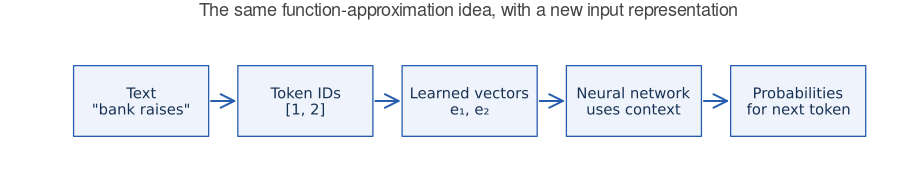

In [2]:
# A small plotting helper; its only job is to draw the explanatory flow diagrams.
function flow_diagram(labels; title="", colors=fill("#EFF4FC", length(labels)))
    n = length(labels)
    p = plot(xlims=(0, 1.8n), ylims=(0, 1.25), axis=false, grid=false,
             legend=false, title=title, size=(900, 190),
             left_margin=3Plots.mm, right_margin=3Plots.mm,
             bottom_margin=2Plots.mm, top_margin=5Plots.mm)
    for i in 1:n
        x = 0.9 + 1.8(i - 1)
        box = Shape([x-.74, x+.74, x+.74, x-.74], [.28, .28, .96, .96])
        plot!(p, box; fillcolor=colors[i], linecolor=blue, linewidth=1.3)
        annotate!(p, x, .62, text(labels[i], 10, :center, "#183153"))
        i < n && plot!(p, [x+.77, x+1.02], [.62, .62]; color=blue, arrow=true)
    end
    p
end
function grouped_bars(labels, values; names, colors, title="", ylabel="", limits=(0,1))
    n, groups = size(values)
    width = 0.75 / groups
    p = plot(xticks=(1:n, labels), xlims=(0.4,n+0.6), ylims=limits,
             ylabel=ylabel, title=title, legend=:topright)
    for group in 1:groups
        x = collect(1:n) .+ (group - (groups+1)/2) * width
        bar!(p, x, values[:, group]; bar_width=0.92width,
             color=colors[group], linecolor=:white, label=names[group])
    end
    p
end
flow_diagram(["Text\n\"bank raises\"", "Token IDs\n[1, 2]",
              "Learned vectors\ne₁, e₂", "Neural network\nuses context",
              "Probabilities\nfor next token"];
             title="The same function-approximation idea, with a new input representation")

## 2. Tokens, vocabulary, and token IDs

A **tokenizer** splits text into units. A **vocabulary** is the set of allowed tokens. A **token ID** is an integer label used to look up a token. The numerical distance between IDs has no linguistic meaning.

Real systems often use subword or byte-based tokenization. To keep every step visible, our tokenizer uses lowercase English words and selected punctuation. This rule is deliberately limited: it is not a general tokenizer for Chinese, numbers, contractions, or arbitrary Unicode text.

Two special tokens will mark sentence boundaries: `<bos>` means **beginning of sequence** and `<eos>` means **end of sequence**. `<unk>` represents an **unknown** token.

In [3]:
tokenize(text::AbstractString) =
    [m.match for m in eachmatch(r"[a-z]+|[.,!?]", lowercase(text))]

demo_tokens = ["bank", "raises", "rates", "."]
demo_vocab = vcat(["<unk>"], demo_tokens)
demo_to_id = Dict(word => i for (i, word) in enumerate(demo_vocab))
demo_text = "Bank raises rates."
demo_ids = [get(demo_to_id, word, 1) for word in tokenize(demo_text)]
println("Text:    ", demo_text)
println("Tokens:  ", tokenize(demo_text))
println("IDs:     ", demo_ids)
println("Lookup:  ", demo_vocab[demo_ids])
println("Unseen token 'river' -> ID ", get(demo_to_id, "river", 1), " = <unk>")

Text:    Bank raises rates.
Tokens:  SubString{String}["bank", "raises", "rates", "."]
IDs:     [2, 3, 4, 5]
Lookup:  ["bank", "raises", "rates", "."]
Unseen token 'river' -> ID 1 = <unk>


## 3. Embeddings are parameters, not supplied definitions

An **embedding** assigns a learned vector $e_j\in\mathbb R^d$ to token ID $j$. In this notebook, Julia stores tokens as **columns** of a matrix:

$$
E\in\mathbb R^{d\times V},\qquad e_j=E[:,j].
$$

The dimension $d$ is a design choice, like the width of a hidden layer. Training changes the entries of $E$, while its shape stays fixed. Our final choice will be $d=32$.

Information can be distributed across many coordinates; a coordinate is not automatically labeled “finance,” “emotion,” or “noun.” Embeddings are useful to the extent that they help the training task. Their coordinates are not uniquely identified semantic variables.

Embedding table size (d, V): (4, 5)
Embedding of bank: Float32[0.12850279, -0.030732436, 0.016152628, -0.0092327455]
Lookup of the sentence has size: (4, 4)


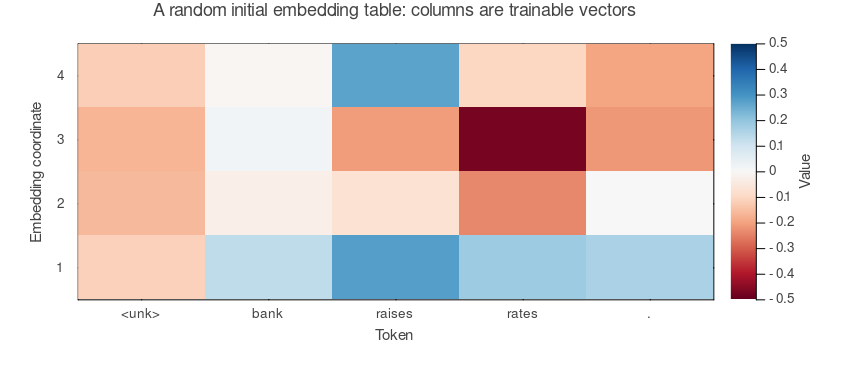

In [4]:
embedding_demo = Flux.Embedding(0.2f0 .* randn(MersenneTwister(11), Float32, 4, length(demo_vocab)))
println("Embedding table size (d, V): ", size(embedding_demo.weight))
println("Embedding of bank: ", embedding_demo(demo_to_id["bank"]))
println("Lookup of the sentence has size: ", size(embedding_demo(demo_ids)))
heatmap(1:length(demo_vocab), 1:4, embedding_demo.weight;
        xticks=(1:length(demo_vocab), demo_vocab), yticks=1:4,
        xlabel="Token", ylabel="Embedding coordinate", color=:RdBu,
        clims=(-0.5, 0.5), colorbar_title="Value",
        title="A random initial embedding table: columns are trainable vectors")

### One embedding update that we can check by hand

Use a vocabulary `[bank, raises, rates]` and the training pair `bank → raises`. Give the input `bank` a one-dimensional embedding $e=0$. Temporarily hold the output weights at $w=(0,1,-1)$, so the three logits (unnormalized scores) are

$$z=(0,e,-e).$$

Softmax converts logits into probabilities. The negative log probability of the correct answer is the **cross-entropy loss**:

$$
p_j=\frac{\exp(z_j)}{\sum_k\exp(z_k)},\qquad
\mathcal L(e)=-\log p_{\text{raises}}
=\log(1+\exp(e)+\exp(-e))-e.
$$

At $e=0$, all three probabilities equal $1/3$, and $\mathcal L'(0)=-1$. With learning rate $\eta=0.1$,

$$e_{\text{new}}=e-\eta\mathcal L'(e)=0.1.$$

The next cell checks the derivative with automatic differentiation and a finite difference. This is the actual route by which prediction error teaches an embedding.

AD gradient: -1.0000 | finite difference: -1.0000
bank embedding: 0.00 -> 0.10
P(raises): 0.3333 -> 0.3672 | loss: 1.0986 -> 1.0019


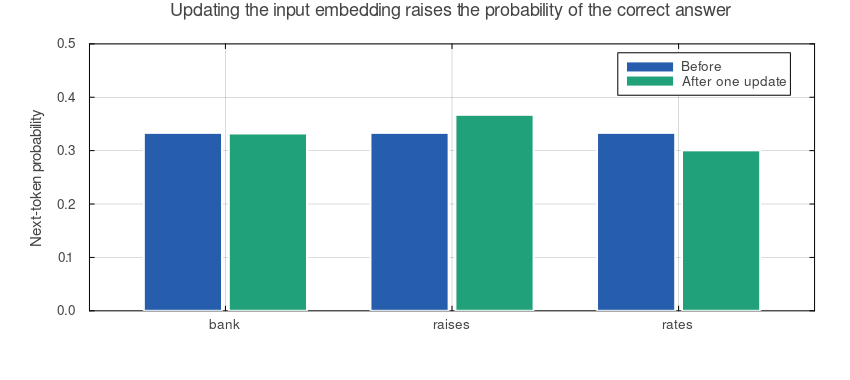

In [5]:
output_weights = Float32[0, 1, -1]
toy_probs(e) = Flux.softmax(output_weights .* e)
toy_loss(e) = -Flux.logsoftmax(output_weights .* e)[2]  # raises is target ID 2
e_before = 0f0
g = Flux.gradient(toy_loss, e_before)[1]
epsilon = 1f-3
g_fd = (toy_loss(e_before + epsilon) - toy_loss(e_before - epsilon)) / (2epsilon)
e_after = e_before - 0.1f0 * g
@printf("AD gradient: %.4f | finite difference: %.4f\n", g, g_fd)
@printf("bank embedding: %.2f -> %.2f\n", e_before, e_after)
@printf("P(raises): %.4f -> %.4f | loss: %.4f -> %.4f\n",
        toy_probs(e_before)[2], toy_probs(e_after)[2], toy_loss(e_before), toy_loss(e_after))
@assert isapprox(g, -1f0; atol=1f-6)
@assert isapprox(g, g_fd; atol=1f-3)
grouped_bars(["bank", "raises", "rates"], hcat(toy_probs(e_before), toy_probs(e_after));
    names=["Before", "After one update"], colors=[blue, green],
    ylabel="Next-token probability", limits=(0, .5),
    title="Updating the input embedding raises the probability of the correct answer")

Only the input embedding of `bank` was involved in that toy lookup. With a separate output matrix, using `raises` as a target does not itself look up its input embedding. Later, all model parameters will be trained jointly. Each occurrence of a token shares the same input embedding parameters.

**Pause and predict:** if the correct answer were `rates` instead, which direction should the update move $e$? Check by changing the target index from `2` to `3` in a copy of the toy loss.

## 4. From a token's identity to its position and context

The initial lookup for `bank` is the same in `the river bank` and `the bank raises rates`. The later network builds a **contextual representation** that can differ between those occurrences.

Order also matters: `the bank raises rates` and `rates raises bank the` contain the same tokens. Our Transformer begins with

$$x_i=e_{t_i}+p_i,$$

where $p_i\in\mathbb R^d$ is a learned **position embedding** for slot $i$. Token embeddings tell the model what is present; position embeddings provide its slot. These position vectors are learned parameters, too.

The matrix of token representations then passes through attention and feed-forward layers. The word “embedding” is sometimes also used for their outputs; here we will distinguish **input token embeddings** $e$ from **contextual hidden states** $h$.

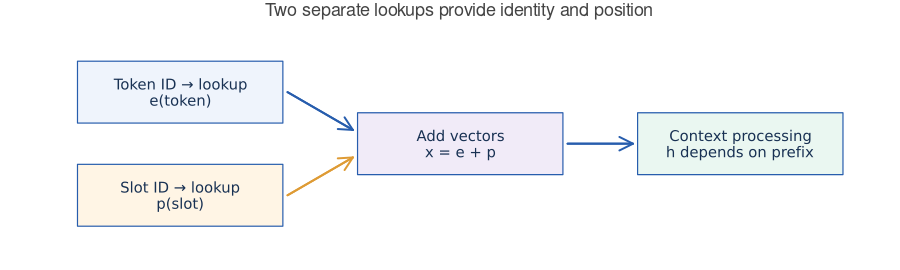

In [6]:
p_position = plot(xlims=(0, 9), ylims=(0, 3), axis=false, grid=false, legend=false,
    title="Two separate lookups provide identity and position", size=(900, 270),
    left_margin=3Plots.mm, right_margin=3Plots.mm,
    bottom_margin=2Plots.mm, top_margin=5Plots.mm)
for (x, y, label, fill) in [(1.5, 2.2, "Token ID → lookup\ne(token)", "#EFF4FC"),
                            (1.5, 0.7, "Slot ID → lookup\np(slot)", "#FFF5E5"),
                            (4.5, 1.45, "Add vectors\nx = e + p", "#F1EBF8"),
                            (7.5, 1.45, "Context processing\nh depends on prefix", "#EAF7F1")]
    plot!(p_position, Shape([x-1.1,x+1.1,x+1.1,x-1.1], [y-.45,y-.45,y+.45,y+.45]);
          fillcolor=fill, linecolor=blue, linewidth=1.2)
    annotate!(p_position, x, y, text(label, 10, :center, "#183153"))
end
plot!(p_position, [2.65,3.35], [2.2,1.65]; color=blue, arrow=true)
plot!(p_position, [2.65,3.35], [.7,1.25]; color=gold, arrow=true)
plot!(p_position, [5.65,6.35], [1.45,1.45]; color=blue, arrow=true)
p_position

## 5. Attention: choose information using the current context

**Self-attention** lets each position combine information from positions in the same sequence. A head forms three projections of its input:

| Object | Intuition | Calculation |
|---|---|---|
| Query $q_i$ | What information am I looking for? | $q_i=W_Qx_i$ |
| Key $k_j$ | How can this position be matched? | $k_j=W_Kx_j$ |
| Value $v_j$ | What information can this position contribute? | $v_j=W_Vx_j$ |

For a query at position $i$, the model scores each eligible key and forms a weighted average:

$$
s_{ji}=\frac{k_j^\top q_i}{\sqrt{d_h}},\qquad
a_{ji}=\frac{\exp(s_{ji})}{\sum_{\ell\ \mathrm{eligible}}\exp(s_{\ell i})},\qquad
o_i=\sum_j a_{ji}v_j.
$$

The weights are computed anew from the current input. The projection matrices are shared learned parameters. A larger attention weight means more weight on a value vector; it is not, by itself, proof of a causal or semantic explanation.

**Our matrix convention:** keys are rows, queries are columns, and softmax operates down each column. Consequently, the matrix formula is $A=\operatorname{softmax}(K^\top Q/\sqrt{d_h})$ and $O=VA$. This is the transpose convention of many textbooks.

Attention weights for query 'bank': Float32[0.164, 0.673, 0.164]
New vector at that query:          Float32[0.164, 0.836]
Column sums:                      Float32[1.0, 1.0, 1.0]


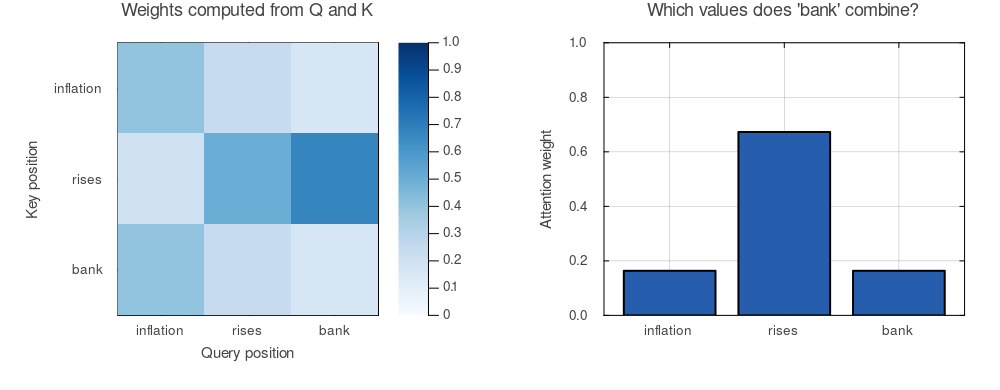

In [7]:
# Hand-chosen Q, K, V: these illustrate the arithmetic, not learned economics.
attention_words = ["inflation", "rises", "bank"]
Q_demo = Float32[1 0 0; 0 1 2]  # shape: 2 coordinates × 3 queries
K_demo = Float32[1 0 1; 0 1 0]
V_demo = Float32[1 0 0; 0 1 1]
scores_demo = K_demo' * Q_demo / sqrt(2f0)
weights_demo = Flux.softmax(scores_demo; dims=1)
mixed_demo = V_demo * weights_demo
println("Attention weights for query 'bank': ", round.(weights_demo[:, 3]; digits=3))
println("New vector at that query:          ", round.(mixed_demo[:, 3]; digits=3))
println("Column sums:                      ", vec(sum(weights_demo; dims=1)))
p_weights = heatmap(1:3, 1:3, weights_demo; clims=(0, 1), color=:Blues,
    xticks=(1:3, attention_words), yticks=(1:3, attention_words), yflip=true,
    xlabel="Query position", ylabel="Key position", title="Weights computed from Q and K")
p_bank = bar(attention_words, weights_demo[:, 3]; color=blue, label=false,
    ylabel="Attention weight", ylims=(0, 1), title="Which values does 'bank' combine?")
plot(p_weights, p_bank; layout=(1, 2), size=(1000, 390),
     margin=7Plots.mm, bottom_margin=11Plots.mm)

## 6. Causal attention: the model must not peek at the answer

When a position predicts the next token, it may use itself and earlier positions. It must not use later positions, which would reveal future targets during training.

We add $-\infty$ to forbidden attention scores before softmax. Their resulting weights are zero:

$$
M_{ji}=\begin{cases}0,&j\leq i,\\-\infty,&j>i.\end{cases}
$$

This is a **causal mask**. Here “causal” refers to the left-to-right information restriction, not identification of an economic causal effect.

During training, all positions can be computed in parallel with this mask. During generation, we append one sampled token at a time. Training uses the actual earlier tokens from the data, a procedure called **teacher forcing**.

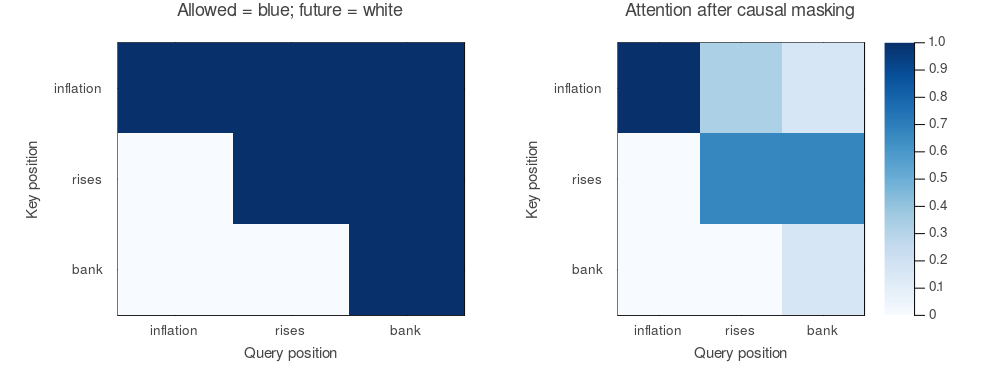

In [8]:
causal_bias(T) = [key <= query ? 0f0 : -Inf32 for key in 1:T, query in 1:T]
causal_demo = Flux.softmax(scores_demo .+ causal_bias(3); dims=1)
p_mask = heatmap(1:3, 1:3, Float32.(isfinite.(causal_bias(3)));
    clims=(0, 1), color=:Blues, colorbar=false, yflip=true,
    xticks=(1:3, attention_words), yticks=(1:3, attention_words),
    xlabel="Query position", ylabel="Key position", title="Allowed = blue; future = white")
p_causal = heatmap(1:3, 1:3, causal_demo; clims=(0, 1), color=:Blues, yflip=true,
    xticks=(1:3, attention_words), yticks=(1:3, attention_words),
    xlabel="Query position", ylabel="Key position", title="Attention after causal masking")
@assert causal_demo[2, 1] == 0f0 && causal_demo[3, 2] == 0f0
@assert all(isapprox.(vec(sum(causal_demo; dims=1)), 1f0; atol=1f-6))
plot(p_mask, p_causal; layout=(1, 2), size=(1000, 390),
     margin=7Plots.mm, bottom_margin=11Plots.mm)

### Where do encoder and decoder fit?

| Architecture | How context is processed | Example use |
|---|---|---|
| Encoder-only | Each position can use the full input, in both directions | Classification with a task head |
| Decoder-only | Each position uses its prefix under a causal mask | Next-token generation |
| Encoder–decoder | An encoder processes the source; a decoder generates a target using source information and its target prefix | Translation |

Embeddings are an input component of these architectures. An encoder is more than an embedding lookup, and a neural decoder is more than looking up token strings. A Transformer encoder need not compress the entire sentence into one vector.

**We now build the decoder-only route.** The tokenizer's `encode`/`decode` operations below are simple ID/string conversions; they are not neural encoder/decoder networks.

## 7. A transparent, small training language

Our synthetic corpus varies the introductory word, subject, direction, and modifier. For example:

```text
when inflation rises today the bank raises rates .
when inflation falls today the bank cuts rates .
if demand rises locally the firms increase production .
```

These are **hand-written rules for an artificial language**. They are not empirical estimates or universal economic relationships. They create a useful context dependency: after `the bank`, the next token depends on an earlier `rises` or `falls`.

We first split **whole unique sentences**, then build the vocabulary and training tensors. Held-out sentences are new combinations from the same grammar. Many fragments are shared across sets, so this is a modest test of grammar recombination, not broad linguistic or economic generalization.

In [9]:
clauses = [
    ("inflation",    "rises", "bank raises rates"),
    ("inflation",    "falls", "bank cuts rates"),
    ("demand",       "rises", "firms increase production"),
    ("demand",       "falls", "firms reduce production"),
    ("productivity", "rises", "workers produce more"),
    ("productivity", "falls", "workers produce less"),
    ("income",       "rises", "households consume more"),
    ("income",       "falls", "households consume less"),
    ("employment",   "rises", "households earn more"),
    ("employment",   "falls", "households earn less"),
]
openers = ["when", "if", "as"]
modifiers = ["today", "locally", "abroad", "recently", "globally", "again"]
sentences = ["$opening $subject $direction $modifier the $ending ."
             for (subject, direction, ending) in clauses
             for opening in openers for modifier in modifiers]
@assert length(unique(sentences)) == length(sentences)
order = randperm(MersenneTwister(27), length(sentences))
n_train = floor(Int, 0.8length(sentences))
train_text = sentences[order[1:n_train]]
heldout_text = sentences[order[n_train+1:end]]
@assert isempty(intersect(Set(train_text), Set(heldout_text)))

vocab = vcat(["<bos>", "<eos>", "<unk>"],
             sort(unique(vcat(tokenize.(train_text)...))))
to_id = Dict(word => i for (i, word) in enumerate(vocab))
BOS, EOS, UNK = to_id["<bos>"], to_id["<eos>"], to_id["<unk>"]
V = length(vocab)
encode_text(text) = Int[get(to_id, word, UNK) for word in tokenize(text)]
decode_ids(ids) = replace(join(vocab[ids], " "), " ." => ".", " ," => ",")
@assert all(word in keys(to_id) for s in heldout_text for word in tokenize(s))
@printf("Unique sentences: %d | training: %d | held-out: %d | vocabulary: %d\n",
        length(sentences), length(train_text), length(heldout_text), V)
println("Training example: ", first(train_text))
println("Held-out example: ", first(heldout_text))

Unique sentences: 180 | training: 144 | held-out: 36 | vocabulary: 36
Training example: if demand falls recently the firms reduce production .
Held-out example: as income rises today the households consume more .


### Turn one sentence into many supervised predictions

For a sentence, append boundary tokens and shift it by one slot:

```text
Input X:   <bos> when inflation rises today the bank raises rates .
Target Y:  when  inflation rises today the bank raises rates . <eos>
```

At input position $i$, the model predicts target $Y_i$ using $X_1,\ldots,X_i$. Every position contributes to the loss. All our sentences have the same length, so no padding or padding-loss mask is needed.

**Shape convention:** token IDs are an integer array `T × B`, where $T$ is sequence length and $B$ is batch size. Embeddings have shape `d × T × B`; logits have shape `V × T × B`.

In [10]:
function language_pairs(texts)
    sequences = [vcat(BOS, encode_text(s), EOS) for s in texts]
    @assert length(unique(length.(sequences))) == 1
    X = hcat([s[1:end-1] for s in sequences]...)
    Y = hcat([s[2:end] for s in sequences]...)
    X, Y
end
X_train, Y_train = language_pairs(train_text)
X_heldout, Y_heldout = language_pairs(heldout_text)
T = size(X_train, 1)
println("Training IDs: ", size(X_train), " = (T, B)")
println("First sentence, shifted prediction pairs:")
for i in 1:T
    @printf("%2d | %-12s -> %s\n", i, vocab[X_train[i, 1]], vocab[Y_train[i, 1]])
end

Training IDs: (10, 144) = (T, B)
First sentence, shifted prediction pairs:
 1 | <bos>        -> if
 2 | if           -> demand
 3 | demand       -> falls
 4 | falls        -> recently
 5 | recently     -> the
 6 | the          -> firms
 7 | firms        -> reduce
 8 | reduce       -> production
 9 | production   -> .
10 | .            -> <eos>


### A baseline: use only the immediately previous token

A **bigram model** estimates $P(t_{i+1}\mid t_i)$ by counting training transitions. We add a small pseudocount to every possible transition, then normalize. It is a useful baseline: can the neural model benefit from longer context?

The two prefixes `when inflation rises today the bank` and `when inflation falls today the bank` end in the same token. A bigram model must give them exactly the same next-token distribution.

In [11]:
bigram_counts = fill(0.1, V, V)  # row: next token; column: current token
for (current, target) in zip(X_train, Y_train)
    bigram_counts[target, current] += 1
end
bigram_probs = bigram_counts ./ sum(bigram_counts; dims=1)
function bigram_loss(X, Y)
    mean(-log(bigram_probs[target, current]) for (current, target) in zip(X, Y))
end
@printf("Bigram train loss: %.4f | held-out loss: %.4f\n",
        bigram_loss(X_train, Y_train), bigram_loss(X_heldout, Y_heldout))
@printf("After bank: P(raises)=%.3f, P(cuts)=%.3f\n",
        bigram_probs[to_id["raises"], to_id["bank"]],
        bigram_probs[to_id["cuts"], to_id["bank"]])

Bigram train loss: 0.8222 | held-out loss: 0.8479
After bank: P(raises)=0.494, P(cuts)=0.408


## 8. Assemble a tiny GPT, one component at a time

We retain the main ingredients of a GPT-style decoder: learned token and position embeddings, causal multi-head self-attention, residual connections, layer normalization, a feed-forward network, and a vocabulary output layer.

Each block follows this **pre-normalization** structure:

$$
U=H+\operatorname{Attention}(\operatorname{LayerNorm}(H)),\qquad
H_{\text{new}}=U+\operatorname{MLP}(\operatorname{LayerNorm}(U)).
$$

- **Multi-head attention:** different learned projections combine context in parallel, then their outputs are concatenated and projected. We use two heads.
- **Residual connection:** add a block's input back to its output, keeping a direct path for information and gradients.
- **Layer normalization:** normalize features separately at each position, with a learned scale and shift.
- **MLP / feed-forward network:** transform each position's features, using the same weights at every position. Our hidden width is $4d$, with a GELU activation.

This is an educational GPT-style implementation, not a reproduction of a released GPT-2 checkpoint. We use a tiny word vocabulary, omit dropout, and keep the input embedding and output weights separate. We train all weights from scratch.

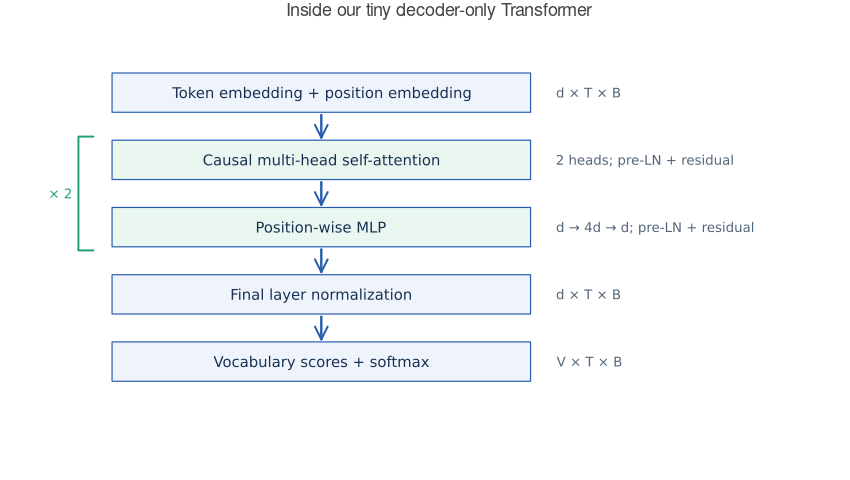

In [12]:
function architecture_diagram()
    labels = ["Token embedding + position embedding", "Causal multi-head self-attention",
              "Position-wise MLP", "Final layer normalization", "Vocabulary scores + softmax"]
    notes = ["d × T × B", "2 heads; pre-LN + residual",
             "d → 4d → d; pre-LN + residual", "d × T × B", "V × T × B"]
    p = plot(xlims=(0, 10), ylims=(0, 7), axis=false, grid=false,
             legend=false, size=(850, 480), title="Inside our tiny decoder-only Transformer")
    ys = [6.1, 4.8, 3.5, 2.2, .9]
    for i in eachindex(labels)
        y = ys[i]
        plot!(p, Shape([.6, 6.2, 6.2, .6], [y-.38, y-.38, y+.38, y+.38]);
              fillcolor=i in (2,3) ? "#EAF7F1" : "#EFF4FC", linecolor=blue, linewidth=1.2)
        annotate!(p, 3.4, y, text(labels[i], 10, :center, "#183153"))
        annotate!(p, 6.55, y, text(notes[i], 9, :left, "#536579"))
        i < length(labels) && plot!(p, [3.4, 3.4], [y-.43, ys[i+1]+.43]; color=blue, arrow=true)
    end
    # The bracket identifies the repeated block, not another operation.
    plot!(p, [.35, .15, .15, .35], [5.25, 5.25, 3.05, 3.05]; color=green, linewidth=2)
    annotate!(p, .05, 4.15, text("× 2", 9, :right, green))
    p
end
architecture_diagram()

### 8a. Multi-head attention

**First pass:** follow `Q, K, V → scores → causal mask → weights → weighted values`. The reshaping only applies the same attention arithmetic to each head and each sentence.

**Second pass — dimensions:** with $H$ heads, each head has $d_h=d/H$ coordinates. We fold the head and batch indices together to call `batched_mul`. The score array is `T_key × T_query × (H*B)`. Softmax over dimension 1 normalizes over eligible keys.

In [13]:
struct CausalAttention{Q,K,VV,O}
    query::Q
    key::K
    value::VV
    output::O
    heads::Int
end
Flux.@layer CausalAttention trainable=(query, key, value, output)

function CausalAttention(d::Int, heads::Int)
    @assert d % heads == 0
    CausalAttention(Dense(d => d), Dense(d => d), Dense(d => d), Dense(d => d), heads)
end

function split_heads(Z, heads)
    d, T, B = size(Z)
    dh = d ÷ heads
    reshape(permutedims(reshape(Z, dh, heads, T, B), (1,3,2,4)), dh, T, heads*B)
end

function attention_forward(a::CausalAttention, X)
    d, T, B = size(X)
    dh = d ÷ a.heads
    Q = split_heads(a.query(X), a.heads)
    K = split_heads(a.key(X), a.heads)
    VV = split_heads(a.value(X), a.heads)
    scores = Flux.NNlib.batched_mul(permutedims(K, (2,1,3)), Q) / sqrt(Float32(dh))
    weights = Flux.softmax(scores .+ reshape(causal_bias(T), T, T, 1); dims=1)
    mixed = Flux.NNlib.batched_mul(VV, weights)
    joined = reshape(permutedims(reshape(mixed, dh, T, a.heads, B), (1,3,2,4)), d, T, B)
    a.output(joined), weights
end
(a::CausalAttention)(X) = first(attention_forward(a, X))

### 8b. A block, then the complete model

Read the two additions in `DecoderBlock` alongside the block equations above. The model adds learned positions, applies two blocks, and returns **logits**. We keep logits separate from probabilities because the loss can use a numerically stable `logsoftmax` internally.

In [14]:
struct DecoderBlock{N1,A,N2,F}
    norm1::N1
    attention::A
    norm2::N2
    feedforward::F
end
Flux.@layer DecoderBlock
DecoderBlock(d, heads) = DecoderBlock(LayerNorm(d), CausalAttention(d, heads),
    LayerNorm(d), Chain(Dense(d => 4d, Flux.gelu), Dense(4d => d)))
function (block::DecoderBlock)(H)
    U = H + block.attention(block.norm1(H))
    U + block.feedforward(block.norm2(U))
end

struct TinyGPT{TE,PE,BL,N,O}
    tokens::TE
    positions::PE
    blocks::BL
    finalnorm::N
    head::O
end
Flux.@layer TinyGPT
function TinyGPT(vocab_size; d=32, heads=2, layers=2, context=16)
    TinyGPT(Embedding(0.02f0 .* randn(Float32, d, vocab_size)),
            Embedding(0.02f0 .* randn(Float32, d, context)),
            [DecoderBlock(d, heads) for _ in 1:layers], LayerNorm(d),
            Dense(d => vocab_size; bias=false))
end

function initial_states(m::TinyGPT, ids)
    T, B = size(ids)
    d, max_context = size(m.positions.weight)
    @assert 1 <= T <= max_context "Prefix exceeds the model's context length."
    m.tokens(ids) .+ reshape(m.positions(1:T), d, T, 1)
end
function hidden_states(m::TinyGPT, ids)
    H = initial_states(m, ids)
    for block in m.blocks
        H = block(H)
    end
    m.finalnorm(H)
end
(m::TinyGPT)(ids) = m.head(hidden_states(m, ids))

GPT_CONFIG = (d=32, heads=2, layers=2, context=16)
Random.seed!(42)
model = TinyGPT(V; GPT_CONFIG...)
untrained_model = deepcopy(model)
embedding_before = copy(model.tokens.weight)
n_parameters = sum(length, Flux.trainables(model))
println("Trainable parameters: ", n_parameters)
println("Input IDs:    ", size(X_train[:, 1:4]))
println("Embeddings:   ", size(initial_states(model, X_train[:, 1:4])))
println("Output logits:", size(model(X_train[:, 1:4])))
@assert size(model(X_train[:, 1:4])) == (V, T, 4)

Trainable parameters: 28288
Input IDs:    (10, 4)
Embeddings:   (32, 10, 4)
Output logits:(36, 10, 4)


## 9. Train by next-token prediction

The objective averages negative log probabilities over every target position and every sentence in a batch:

$$
\mathcal L(\theta)=-\frac{1}{BT}\sum_{b=1}^B\sum_{i=1}^T
\log P_\theta(Y_{ib}\mid X_{1b},\ldots,X_{ib}).
$$

`Flux.logitcrossentropy` computes this loss directly from logits and one-hot targets. A one-hot target marks the observed class; it is separate from the learned input embedding.

**Perplexity** is $\exp(\mathcal L)$ when loss uses natural logarithms. Lower is better on the same tokenization and evaluation sample. It does not measure truthfulness or economic validity.

Below we use Adam, random mini-batches of whole sentences, and a fixed number of updates. Held-out data are evaluated for reporting, not used for gradient updates or checkpoint selection. Re-running this cell creates a fresh model, so it does not silently continue a previous training run.

In [15]:
function lm_loss(m, X, Y)
    logits = reshape(m(X), V, :)
    targets = Flux.onehotbatch(vec(Y), 1:V)
    Flux.logitcrossentropy(logits, targets)
end

function train_tiny_gpt(; steps=800, batch_size=32, learning_rate=0.003f0, seed=42,
                        config=GPT_CONFIG)
    Random.seed!(seed)
    m = TinyGPT(V; config...)
    initial = deepcopy(m)
    opt = Flux.setup(Flux.Adam(learning_rate), m)
    rng = MersenneTwister(seed + 1)
    history = (step=Int[], train=Float64[], heldout=Float64[])
    function record!(step)
        train = Float64(lm_loss(m, X_train, Y_train))
        heldout = Float64(lm_loss(m, X_heldout, Y_heldout))
        push!(history.step, step); push!(history.train, train); push!(history.heldout, heldout)
        @printf("step %4d | train %.4f | held-out %.4f | held-out perplexity %.2f\n",
                step, train, heldout, exp(heldout))
        flush(stdout)
    end
    record!(0)
    started = time()
    for step in 1:steps
        chosen = rand(rng, 1:size(X_train, 2), batch_size)
        X, Y = X_train[:, chosen], Y_train[:, chosen]
        loss, grads = Flux.withgradient(m) do candidate
            lm_loss(candidate, X, Y)
        end
        isfinite(loss) || error("Non-finite training loss at step $step")
        Flux.update!(opt, m, grads[1])
        (step % 100 == 0 || step == steps) && record!(step)
    end
    elapsed = time() - started
    @printf("Elapsed after initial evaluation (includes gradient compilation): %.1f seconds\n", elapsed)
    m, initial, history, elapsed
end

model, untrained_model, history, training_seconds = train_tiny_gpt()
embedding_before = copy(untrained_model.tokens.weight)

step    0 | train 4.1490 | held-out 4.1245 | held-out perplexity 61.84
step  100 | train 0.5439 | held-out 0.5766 | held-out perplexity 1.78
step  200 | train 0.5308 | held-out 0.5781 | held-out perplexity 1.78
step  300 | train 0.5270 | held-out 0.5810 | held-out perplexity 1.79
step  400 | train 0.5210 | held-out 0.5952 | held-out perplexity 1.81
step  500 | train 0.5205 | held-out 0.5932 | held-out perplexity 1.81
step  600 | train 0.5238 | held-out 0.5792 | held-out perplexity 1.78
step  700 | train 0.5246 | held-out 0.5757 | held-out perplexity 1.78
step  800 | train 0.5206 | held-out 0.5865 | held-out perplexity 1.80
Elapsed after initial evaluation (includes gradient compilation): 26.4 seconds


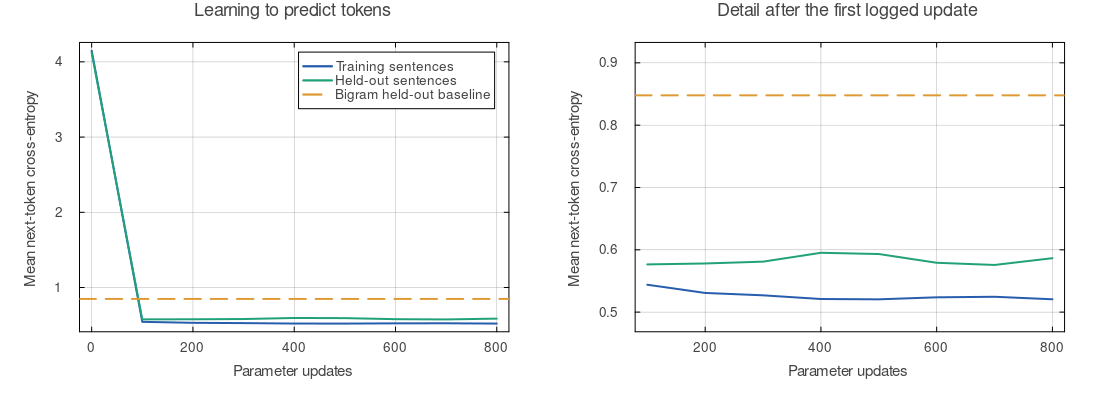

In [16]:
p_loss = plot(history.step, history.train; label="Training sentences", color=blue,
    xlabel="Parameter updates", ylabel="Mean next-token cross-entropy",
    title="Learning to predict tokens")
plot!(p_loss, history.step, history.heldout; label="Held-out sentences", color=green)
hline!(p_loss, [bigram_loss(X_heldout, Y_heldout)]; color=gold, linestyle=:dash,
       label="Bigram held-out baseline")
detail_low = min(minimum(history.train[2:end]), minimum(history.heldout[2:end]))
detail_high = max(maximum(history.train[2:end]), maximum(history.heldout[2:end]),
                  bigram_loss(X_heldout, Y_heldout))
p_detail = plot(history.step[2:end], history.train[2:end]; color=blue, legend=false,
    xlabel="Parameter updates", ylabel="Mean next-token cross-entropy",
    ylims=(0.9detail_low, 1.1detail_high), title="Detail after the first logged update")
plot!(p_detail, history.step[2:end], history.heldout[2:end]; color=green)
hline!(p_detail, [bigram_loss(X_heldout, Y_heldout)]; color=gold, linestyle=:dash)
plot(p_loss, p_detail; layout=(1,2), size=(1100, 410),
     margin=7Plots.mm, bottom_margin=12Plots.mm)

## 10. Evaluate what was actually learned

We compare an untrained network, a bigram baseline, and the trained GPT on exactly the same targets. Accuracy is the fraction of positions whose highest-probability token equals the observed target. Some positions have multiple valid continuations, so perfect accuracy is not expected.

The held-out split shares the corpus grammar and many prefixes with training. Better performance supports learning within this small constructed task; it does not establish knowledge of natural language in general. A larger network can also memorize a small corpus. Keep training and held-out curves visible together.

Loss need not reach zero even for this grammar: a shared prefix may have several valid continuations. At `<bos>`, for example, the opening word can be `when`, `if`, or `as`. The model must learn a distribution over such choices.

In [17]:
function token_accuracy(m, X, Y)
    guesses = Flux.onecold(reshape(m(X), V, :), 1:V)
    mean(guesses .== vec(Y))
end
println("Model                     train loss  held-out loss  held-out PPL  held-out accuracy")
println("--------------------------------------------------------------------------------")
for (label, m) in [("Untrained tiny GPT", untrained_model), ("Trained tiny GPT", model)]
    train_loss = lm_loss(m, X_train, Y_train)
    heldout_loss = lm_loss(m, X_heldout, Y_heldout)
    @printf("%-25s %9.4f %13.4f %13.2f %17.1f%%\n", label,
            train_loss, heldout_loss, exp(heldout_loss), 100token_accuracy(m, X_heldout, Y_heldout))
end
bigram_accuracy = mean(argmax(bigram_probs[:, current]) == target
                       for (current, target) in zip(X_heldout, Y_heldout))
@printf("%-25s %9.4f %13.4f %13.2f %17.1f%%\n", "Bigram baseline",
    bigram_loss(X_train, Y_train), bigram_loss(X_heldout, Y_heldout),
    exp(bigram_loss(X_heldout, Y_heldout)), 100bigram_accuracy)

Model                     train loss  held-out loss  held-out PPL  held-out accuracy
--------------------------------------------------------------------------------
Untrained tiny GPT           4.1490        4.1245         61.84               1.9%
Trained tiny GPT             0.5206        0.5865          1.80              68.9%
Bigram baseline              0.8222        0.8479          2.33              53.9%


### Does earlier context change the next-token distribution?

These two prompts differ only in `rises` versus `falls`. Both end with `bank`, so the bigram prediction is identical. Our grammar assigns `raises` to one and `cuts` to the other. This is a controlled sensitivity probe of the learned mapping, not an economic causal experiment.

The prompts are **illustrative probes**, not guaranteed to be entirely absent from training. The sentence-level held-out evaluation above is reported separately.

Prompt: when inflation rises today the bank
  raises       0.9980
  cuts         0.0006
  households   0.0002
  produce      0.0002
  consume      0.0001
Prompt: when inflation falls today the bank
  cuts         0.9981
  production   0.0006
  raises       0.0002
  earn         0.0002
  produce      0.0001


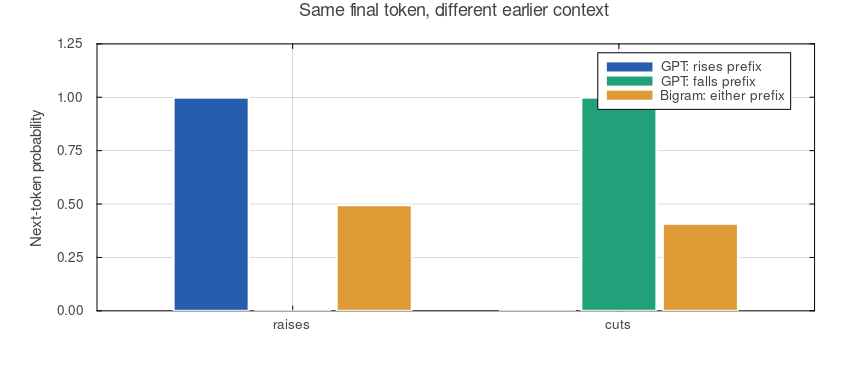

In [18]:
function prefix_ids(prompt)
    ids = encode_text(prompt)
    any(==(UNK), ids) && error("Prompt contains an unknown token; use words from vocab.")
    vcat(BOS, ids)
end
function next_probs(m, prompt; temperature=1f0)
    temperature > 0 || error("Use a positive temperature for probabilities.")
    ids = prefix_ids(prompt)
    scores = vec(m(reshape(ids, :, 1))[:, end, 1])
    Flux.softmax(scores ./ Float32(temperature))
end
function show_top_tokens(m, prompt; k=5)
    p = next_probs(m, prompt)
    println("Prompt: ", prompt)
    for j in sortperm(p; rev=true)[1:k]
        @printf("  %-12s %.4f\n", vocab[j], p[j])
    end
end
up_prompt = "when inflation rises today the bank"
down_prompt = "when inflation falls today the bank"
show_top_tokens(model, up_prompt)
show_top_tokens(model, down_prompt)
actions = [to_id[word] for word in ["raises", "cuts"]]
probe = hcat(next_probs(model, up_prompt)[actions], next_probs(model, down_prompt)[actions],
             bigram_probs[actions, to_id["bank"]])
grouped_bars(["raises", "cuts"], probe;
    names=["GPT: rises prefix", "GPT: falls prefix", "Bigram: either prefix"],
    colors=[blue, green, gold], limits=(0, 1.25), ylabel="Next-token probability",
    title="Same final token, different earlier context")

### Inspect the learned attention, without overinterpreting it

We plot the last block's two heads for the rising-inflation prompt. Keys are rows, queries are columns. Forbidden future positions remain white. The heads need not specialize into named linguistic roles, and a single heatmap is not a complete explanation of the model's prediction.

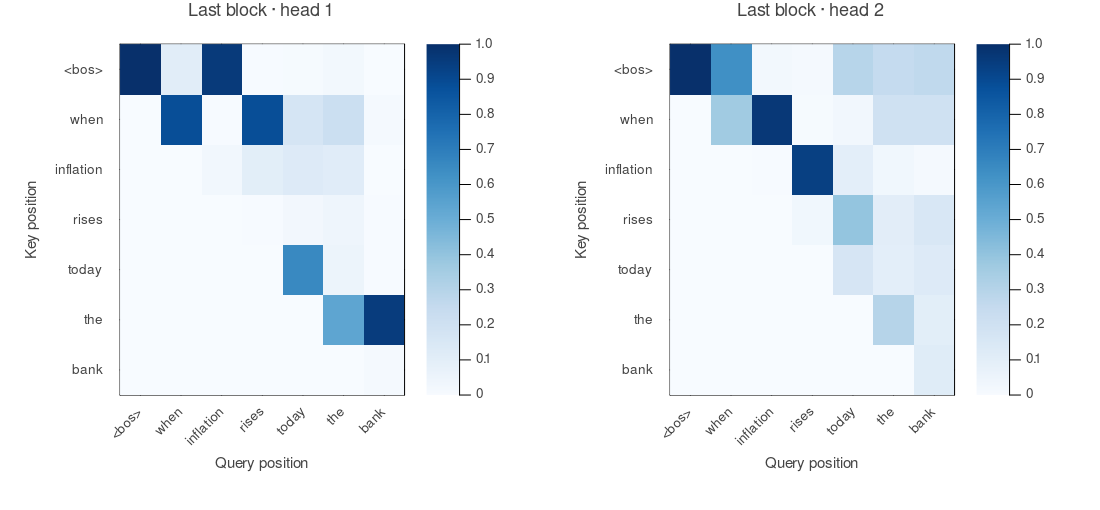

In [19]:
function block_attention(m, ids; layer=length(m.blocks))
    H = initial_states(m, ids)
    for index in 1:layer-1
        H = m.blocks[index](H)
    end
    block = m.blocks[layer]
    _, weights = attention_forward(block.attention, block.norm1(H))
    T, B = size(ids)
    reshape(weights, T, T, block.attention.heads, B)
end
inspect_ids = prefix_ids(up_prompt)
attention_maps = block_attention(model, reshape(inspect_ids, :, 1))
labels = vocab[inspect_ids]
attention_plots = [heatmap(1:length(labels), 1:length(labels), attention_maps[:, :, head, 1];
    xticks=(1:length(labels), labels), yticks=(1:length(labels), labels),
    xrotation=45, yflip=true, color=:Blues, clims=(0, 1),
    xlabel="Query position", ylabel="Key position", title="Last block · head $head")
    for head in 1:2]
plot(attention_plots...; layout=(1,2), size=(1100, 510),
     margin=8Plots.mm, bottom_margin=17Plots.mm)

### Did the input embedding table change?

The next figure measures how far each token's vector moved from its own initialization. It verifies that embeddings participated in training. Movement alone does not prove a semantic interpretation, and a 2D projection of a 32D table would not preserve all its information.

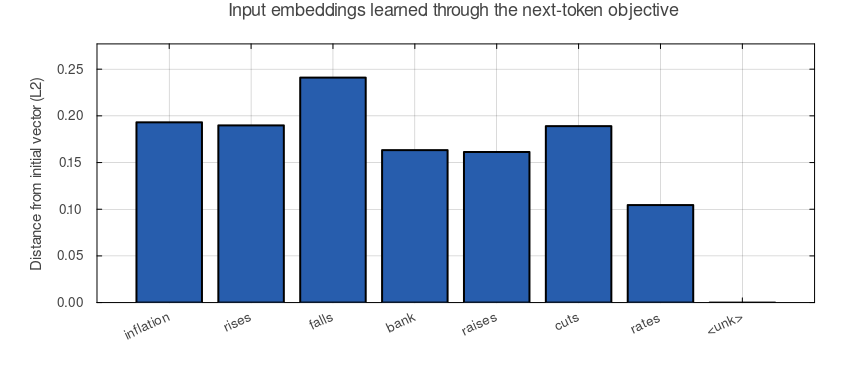

In [20]:
embedding_movement = vec(sqrt.(sum(abs2, model.tokens.weight - embedding_before; dims=1)))
selected_words = ["inflation", "rises", "falls", "bank", "raises", "cuts", "rates", "<unk>"]
selected_ids = [to_id[word] for word in selected_words]
bar(selected_words, embedding_movement[selected_ids]; color=blue, label=false,
    ylabel="Distance from initial vector (L2)", xrotation=25,
    ylims=(0, 1.15maximum(embedding_movement[selected_ids])),
    title="Input embeddings learned through the next-token objective")

## 11. Generate: repeatedly append a predicted token

**Autoregressive generation** repeats the same operation: compute a next-token distribution, select a token, append it, and recompute. Stop at `<eos>` or the length limit.

- **Greedy decoding** chooses the highest-probability token.
- **Sampling** draws a token from the distribution.
- **Temperature** rescales logits before sampling. Lower positive values make the distribution sharper; higher values make it flatter. Temperature does not add knowledge.

We use the **same sampler, seed, prompt, and temperature** to compare the untrained and trained networks. Special tokens are not manually banned; odd outputs from the untrained model are part of the comparison. We stop when the fixed context window is full rather than silently discarding earlier tokens.

In [21]:
function sample_token(rng, probabilities)
    u = rand(rng)
    cumulative = cumsum(probabilities)
    something(findfirst(x -> x >= u, cumulative), length(probabilities))
end

function generate(m, prompt=""; max_new_tokens=14, temperature=0.8f0,
                  greedy=false, seed=7)
    temperature > 0 || error("Temperature must be positive; use greedy=true for argmax.")
    ids = prefix_ids(prompt)
    max_context = size(m.positions.weight, 2)
    length(ids) <= max_context || error("Prompt exceeds the context window.")
    rng = MersenneTwister(seed)
    emitted = copy(ids[2:end])
    for _ in 1:max_new_tokens
        length(ids) >= max_context && break
        logits = vec(m(reshape(ids, :, 1))[:, end, 1])
        p = Flux.softmax(logits ./ Float32(temperature))
        next = greedy ? argmax(p) : sample_token(rng, p)
        next == EOS && break
        push!(ids, next)
        push!(emitted, next)
    end
    decode_ids(emitted)
end

generation_prompt = "when inflation rises"
println("Same sampler, temperature=0.8, seed=7:")
println("Before training: ", generate(untrained_model, generation_prompt))
println("After training:  ", generate(model, generation_prompt))
println("\nGreedy continuations:")
for prompt in ["when inflation rises", "when inflation falls", "if demand rises", "as income falls"]
    println("  ", generate(model, prompt; greedy=true))
end
println("\nSample from a sentence boundary:")
for seed in 1:3
    println("  ", generate(model; seed=seed))
end

Same sampler, temperature=0.8, seed=7:
Before training: when inflation rises produce when productivity bank households increase <unk> employment if households when globally
After training:  when inflation rises recently the bank raises rates.

Greedy continuations:
  when inflation rises today the bank raises rates.
  when inflation falls recently the bank cuts rates.
  if demand rises today the firms increase production.
  as income falls globally the households consume less.

Sample from a sentence boundary:
  as inflation falls today the bank cuts rates.
  when demand rises globally the firms increase production.
  as demand falls today the firms reduce production.


## 12. Check the mechanism, not just the training curve

The following checks test concrete properties:

1. Whole training and held-out sentences are disjoint.
2. All learned parameters and losses are finite, and training loss fell.
3. Attention columns sum to one and future positions receive zero weight.
4. Replacing future input tokens leaves earlier logits unchanged.
5. Predicting from a prefix agrees with the corresponding position in the full masked sequence.
6. Used input embeddings moved; the never-used `<unk>` input column stayed fixed. This last property relies on our separate input and output weights and absence of weight decay.

These are implementation and learning checks. They do not turn the synthetic held-out set into evidence of general intelligence.

In [22]:
@assert isempty(intersect(Set(train_text), Set(heldout_text)))
@assert all(all(isfinite, parameter) for parameter in Flux.trainables(model))
@assert all(isfinite, history.train) && all(isfinite, history.heldout)
@assert last(history.train) < first(history.train)

check_X = copy(X_heldout[:, 1:1])
check_A = block_attention(model, check_X)
@assert maximum(abs.(sum(check_A; dims=1) .- 1)) < 1f-5
future_weights = [check_A[key, query, head, 1]
                  for key in 1:T for query in 1:T for head in 1:2 if key > query]
@assert maximum(abs, future_weights) < 1f-7

cut = 4
changed_X = copy(check_X)
changed_X[cut+1:end, 1] .= to_id["cuts"]
future_effect = maximum(abs.(model(check_X)[:, 1:cut, :] - model(changed_X)[:, 1:cut, :]))
@assert future_effect < 1f-5
full_logits = model(check_X)
prefix_error = maximum(maximum(abs.(model(check_X[1:i, :])[:, end, 1] - full_logits[:, i, 1]))
                       for i in 1:T)
@assert prefix_error < 2f-5
@assert embedding_movement[to_id["bank"]] > 1f-4
@assert embedding_movement[UNK] < 1f-7
@printf("All checks passed. Future-token effect: %.2e | prefix/full error: %.2e\n",
        future_effect, prefix_error)

All checks passed. Future-token effect: 0.00e+00 | prefix/full error: 2.03e-06


## 13. Small experiments you can now understand

Change **one thing at a time**, restart, and run all cells. Compare held-out performance as well as training loss.

| Experiment | Change | What to inspect |
|---|---|---|
| Representation width | Use `d=16` instead of `32` in `GPT_CONFIG` | Parameter count, loss, and runtime |
| Training length | Set `steps=100` or `steps=1600` | Underfitting, improvement, or a widening train/held-out gap |
| Sampling | Change `temperature` while keeping prompt and seed fixed | Diversity and grammar mistakes |
| Context sensitivity | Replace `rises` with `falls` in a prompt | The full next-token distribution, not only one sample |
| Mask audit | Inspect the causal checks above | Why future information must stay unavailable |

The default `GPT_CONFIG` is two layers, two heads, width 32, and context length 16. The embedding width must be divisible by the number of heads, and the context must fit a training sentence. The default attention plots and checks assume two heads.

### What this notebook establishes

You have trained a small autoregressive Transformer from random initialization. Token embeddings and network weights learned jointly through prediction loss. Attention combined eligible context, and repeated next-token predictions produced complete toy sentences.

The corpus has only 180 sentences from ten hand-written clauses. Its vocabulary, grammar, and context window are narrow. Fluent-looking output can still be a memorized pattern; economic statements remain properties of the supplied grammar. Training a broadly capable language model requires a much larger undertaking.

### A short glossary

| Term | Meaning here |
|---|---|
| Token / vocabulary | A text unit / the allowed units |
| Token ID | A fixed integer lookup label |
| Embedding | A learned vector associated with an ID |
| Hidden state | An intermediate representation, possibly contextual |
| Logit / softmax | An unnormalized score / a map from scores to probabilities |
| Cross-entropy | Negative log probability of observed targets, averaged here |
| Attention head | One set of query, key, value, and context-mixing computations |
| Causal mask | A restriction that prevents access to later positions |
| Context window | The maximum prefix length supported by this model |
| Batch | Several sentences processed for one parameter update |
| Teacher forcing | Training with actual earlier tokens rather than sampled ones |
| Autoregressive generation | Append a predicted token and repeat |
| Pretraining / fine-tuning | Initial training / further training of existing weights |

### Sources and further reading

- [Hugging Face: Tokenizers](https://huggingface.co/docs/course/chapter2/4) — word, subword, and other tokenization choices.
- [Bengio et al. (2003): A Neural Probabilistic Language Model](https://jmlr.org/papers/v3/bengio03a.html) — learning word representations with a probability model.
- [Vaswani et al. (2017): Attention Is All You Need](https://arxiv.org/abs/1706.03762) — attention and the original encoder–decoder Transformer; our decoder-only teaching model is a simplified adaptation.
- [Flux: built-in layers](https://fluxml.ai/Flux.jl/stable/reference/models/layers/) and [training](https://fluxml.ai/Flux.jl/stable/guide/training/training/) — implementation references. The saved run records the actual installed versions in Section 0.

All examples, diagrams, code, and synthetic sentences in this notebook were constructed for this tutorial.